<a href="https://colab.research.google.com/github/sessm216/randomprojects/blob/main/trainsim_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Train simulation design thinking project

Project goal: 'solving the train problem in Spain'

What we did:

1.   Design thinking problem where we interviewd people about their experiences with trains.
2.   Identified a specific need: **in our state there are only high speed trains, usually very expensive connecting long distances**. As a result, no one uses the train for shorter distances.
3. Question: could we create train routes covering median/long distances in our state?
4. **Would people travel more by train if they were cheaper?**
5. Inspiration: regional train network in Germany, where cheaper trains (Regional) travel slower but still cover long distances (+150km).
6. Checking our solution: **running a simulation to see whether people choose the cheaper slower train (train 1) or still travel high speed**.
7. We ask ourselves: what do passengers value more: saving money, travel time, etc.


## My task: quantitatively evaluate passengers priorities and develop the simulation in Python.

### Quantitative description of passengers priorities.
* Passengers criteria: price, travel time (train speed) and waiting time.
* Passengers will make the decision of changing from one train to another throughout the day when a train arrives at the station.

How did I model that? **Probability function**

$$
P(change)=\Delta waitingtime*p(waitingtime)+ \Delta savings*p(savings)++\Delta traveltime*p(traveltime)
$$

* $p(criterion)$ describes how important that factor is to passengers. It follows $p \epsilon (0,100)$ and will later be normalized.

Examples of $p$ combinations:
| p(waitingtime) | p(savings)   | p(timelefttotravel)| Meaning |
| :--- | :---: | ---: | ---:|
| 50 | 0 | 0 | They don't care how expensive the train is, they don't want to wait for it. High probability of changing towards the faster train |
|  2.5 | 50 | 2.5 | The most important thing is saving money. Slower cheaper train will be more popular |

**What are the $\Delta variations$?**

When a train arrives those waiting for the other one consider changing their mind. They analyze the relative change in price, waiting time and travel time.

##Codebase details
###Getting started and physical parameters:

About the trains:

*   We've got 2 trains: 1 and 2
*   All parameters related to trains are declared as np.array of dimension 2. Example: v=np.array[speedoftrain1,speedoftrain2]
* Vector for trains: v, x, siguienteparada, posicion.

About the stations:
*   We've got 3 stations: A,B or C.
*   distancias=np.array[distanceA-B,distanceB-C]


Other initial conditions:
*    Max capacity of the trains: nmax
* Hours of service: horas_operacion

Meaning of variables:

* direccion: a 2 dimension array telling me in which direction each train goes [directiontrain1,directiontrain2].
* posicion: 2-dim array telling me at which station the train is. 0=A, 1=B, 2=C.
* t: 2-dim array telling me how much time left for each train to arrive at each station. It is first declared as distanceAB/v *60 (minutes)
* ntransportados: 2x3 matrix telling me how many passengers there are at each train wanting to go to which station. The initial condition is shown in the table below:

| Station | A   | B | C |
| :--- | :---: | ---: | ---:|
| Train 1 | 0 | nmax*0.5 | nmax*0.5 |
| Train 2  | 0 | nmax*0.5 | nmax*0.5 |
*   No passengers inside the train want to go to A since they are already there
*   Half the passengers want to go to B and other half to C. This can be changed or computed considering randomness.


Meaning of genteesperando variable:
*   Variable telling us how many passengers are at each station wanting to get in a train when it arrives. Valued can be changed or computed randomly.

| Station | A   | B | C |
| :--- | :---: | ---: | ---:|
| Train 1 | 0 | 190 | 190 |
| Train 2  | 0 | 190 | 190 |

###Variables to compute efficiency of that rail system
* Parameters to describe the efficiency of each set of probabilities, meaning, to describe whether people can conmute given those schedules, train speed, prices, etc.
* Important to keep in miind IRL meaning: if a train is too empty, that line would not exist. We want to check that two trains covering the same route can coexist and that the slower one is useful too, bc some people will prefer to pay less.
* pasajerostotales: total number of passengers that will have travelled at the end of the day. It us updated after each journey.
* viajes: number of effective journeys the trains completed.
* ganancia: how much money people have paid at the end of the day
* gentefuera: used to compute how many people there are left out.

Questions:

*   Why does gentefuera exist? Let's say there's a 300km/h train for free. Everyone will want to ride it but not everyone fits. People will be left out and disatisfied. We want people to prefer the cheaper, slower option (that was the premise of the experiment) but not crazily. Can also be used to measure whether our initial conditions are realistic: it is unlikely that a 300km/h train for free service will be offered.


In [ ]:
# -*- coding: utf-8 -*-
"""
Versión adaptada con bucles para recorrer múltiples valores de
velocidades, precios y probabilidades, imprimiendo los resultados en pantalla.
"""

import numpy as np
import random
import itertools

# ==========================================
# 1. Parameters to go over.
# ==========================================
# Different values
lista_velocidades = [
    np.array([100, 200]),
    np.array([80, 220])
]

lista_precios = [
    np.array([10.0, 30.0]),
    np.array([5.0, 40.0])
]

lista_probabilidades = [
    np.array([10, 25.0, 10.5]),
    np.array([10.0, 25.0, 10.0])
]

# Fixed distances and max number of passengers
distancias = np.array([100, 100])  # A–B y B–C
nmax = 400

# ==========================================
# 2. Multiparameter simulation loop
# ==========================================
print(f"{'Velocidades':<20} | {'Precios':<15} | {'Probabilidades':<25} | {'Pasajeros/Viaje T1':<20} | {'Pasajeros/Viaje T2':<20}")
print("-" * 115)

for v, x, probabilidades in itertools.product(lista_velocidades, lista_precios, lista_probabilidades):

    # --- Initializating variables for each loop
    horas_operacion = (24 - 6) * 60
    t = np.array((distancias[0] / v) * 60)

    posicion = np.zeros(2, dtype=int)
    direccion = np.ones(2, dtype=int)
    tiemporestante = np.array([(distancias[0] / v[i]) * 60 for i in range(2)])
    siguienteparada = np.zeros(2, dtype=int)

    ntransportados = np.zeros((2, 3))
    for m in range(2):
        for l in range(3):
            if l == 0:
                ntransportados[m, l] = 0
            else:
                ntransportados[m, l] = nmax * 0.5

    genteesperando = np.zeros((2, 3))
    for m in range(2):
        for l in range(3):
            if l == 1:
                genteesperando[m, l] = 190
            else:
                genteesperando[m, l] = 190

    pasajerostotales = np.zeros(2)
    viajes = np.zeros((2, 3))
    gentefuera = 0

    # --- 1 day sim
    for k in range(1081):
        for tren in range(2):
            tiemporestante[tren] -= 1

            if tiemporestante[tren] <= 0:
                genteesperando = genteesperando * random.uniform(0.9, 1.1)
                posicion[tren] += direccion[tren]
                viajes[tren, posicion[tren]] += 1
                pasajerostotales[tren] += ntransportados[tren, posicion[tren]]
                ntransportados[tren, posicion[tren]] = 0

                otrotren = 1 - tren
                if tiemporestante[otrotren] > 20:
                    ahorro = (x[otrotren] - x[tren]) / x[otrotren]
                    tiempoviaje = (t[otrotren] - t[tren]) / t[otrotren]
                    espera = tiemporestante[otrotren] - 20
                    prob = (espera) * probabilidades[0] / 100 + ahorro * probabilidades[1] / 100 + tiempoviaje * probabilidades[2] / 100
                    prob = max(0, min(prob, 1))
                    pasajerosextra = genteesperando[otrotren, posicion[tren]] * prob
                else:
                    pasajerosextra = 0

                if (posicion[tren] == 2) or (posicion[tren] == 0):
                    direccion[tren] *= (-1)
                siguienteparada[tren] = posicion[tren] + direccion[tren]

                if posicion[tren] == 1:
                    ntransportados[tren, siguienteparada[tren]] += genteesperando[tren, posicion[tren]]
                    if ntransportados[tren, siguienteparada[tren]] > 400:
                        sitioslibres = 0
                        ntransportados[tren, siguienteparada[tren]] = 400
                        gentefuera += pasajerosextra
                    else:
                        sitioslibres = max(0, 300 - ntransportados[tren, siguienteparada[tren]])
                        gentefuera += max(0, pasajerosextra - sitioslibres)
                        ntransportados[tren, siguienteparada[tren]] += sitioslibres
                else:
                    q = random.uniform(0.3, 0.7)
                    genteesperando[tren, posicion[tren]] += pasajerosextra
                    echamosgente = genteesperando[tren, posicion[tren]] - 400
                    if echamosgente > 0:
                        gentefuera += echamosgente
                        ntransportados[tren, siguienteparada[tren]] += 400 * q
                        ntransportados[tren, siguienteparada[tren] + direccion[tren]] += 400 * (1 - q)
                    else:
                        ntransportados[tren, siguienteparada[tren]] += genteesperando[tren, posicion[tren]] * q
                        ntransportados[tren, siguienteparada[tren] + direccion[tren]] += genteesperando[tren, posicion[tren]] * (1 - q)

                if 0 <= siguienteparada[tren] <= 2:
                    tiemporestante[tren] = (distancias[0] / v[tren]) * 60
                else:
                    tiemporestante[tren] = 9999

    # Results
    pasajerosporviaje = np.zeros(2)
    for m in range(2):
        aux = pasajerostotales[m]
        aux2 = sum(viajes[m, :])
        if aux2 > 0:
            pasajerosporviaje[m] = aux / aux2
        else:
            pasajerosporviaje[m] = 0

    # --- Printing
    print(f"{str(v):<20} | {str(x):<15} | {str(probabilidades):<25} | {pasajerosporviaje[0]:<20.2f} | {pasajerosporviaje[1]:<20.2f}")

Velocidades          | Precios         | Probabilidades            | Pasajeros/Viaje T1   | Pasajeros/Viaje T2  
-------------------------------------------------------------------------------------------------------------------
[100 200]            | [10. 30.]       | [10.  25.  10.5]          | 210.16               | 286.33              
[100 200]            | [10. 30.]       | [10. 25. 10.]             | 273.91               | 299.94              
[100 200]            | [ 5. 40.]       | [10.  25.  10.5]          | 193.94               | 272.97              
[100 200]            | [ 5. 40.]       | [10. 25. 10.]             | 218.34               | 290.20              
[ 80 220]            | [10. 30.]       | [10.  25.  10.5]          | 279.58               | 295.78              
[ 80 220]            | [10. 30.]       | [10. 25. 10.]             | 269.66               | 292.45              
[ 80 220]            | [ 5. 40.]       | [10.  25.  10.5]          | 232.18               | 2

### How to interpret these results:
* We are interested in equal or more people travelling in train 1 (cheaper) than train 2 (+ expensive).
* We want the average occupancy rate to be equal or higher for train 1.
* We see that for speeds [100,200] and probs [10.  25.  10.5]   train 1 on average has 80 less passengers than train 2(272).
* What this means in real life? Either we keep the probabilities and make the train faster or the price cheaper; or we convince people to care less about those aspects thus changing the probabilities.


### Playing with the code
* We can change the initial number of passengers, people waiting at each station and people changing their mind. A randomness element can be added.
* For example, the initial amount of people waiting is 190, close to nmax*05 (currently set to 200) and the initial amount of carried passengers is nmax*0.5. This is the reason why average occupancy rate concentrates towards 200. We can wing it a bit.



Velocidades          | Precios         | Probabilidades            | Pasajeros/Viaje T1   | Pasajeros/Viaje T2  
-------------------------------------------------------------------------------------------------------------------
[100 200]            | [10. 30.]       | [10.  25.  10.5]          | 196.14               | 274.62              
[100 200]            | [10. 30.]       | [10. 25. 10.]             | 221.08               | 278.47              
[100 200]            | [ 5. 40.]       | [10.  25.  10.5]          | 203.57               | 289.63              
[100 200]            | [ 5. 40.]       | [10. 25. 10.]             | 261.34               | 299.20              
[ 80 220]            | [10. 30.]       | [10.  25.  10.5]          | 277.52               | 291.03              
[ 80 220]            | [10. 30.]       | [10. 25. 10.]             | 253.97               | 285.02              
[ 80 220]            | [ 5. 40.]       | [10.  25.  10.5]          | 272.26               | 2

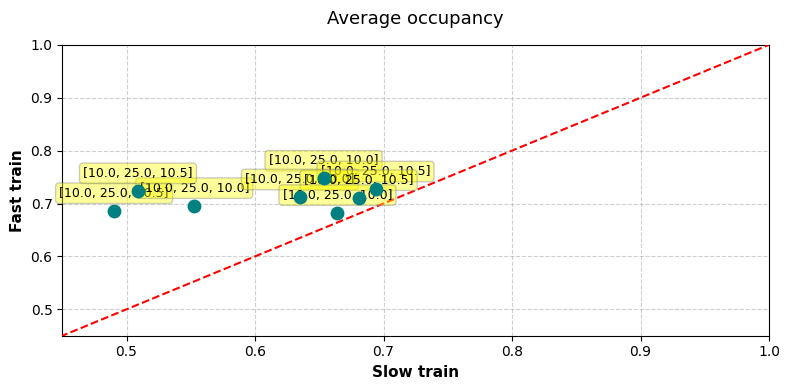

In [17]:
# -*- coding: utf-8 -*-
"""
Versión adaptada con bucles para recorrer múltiples valores de
velocidades, precios y probabilidades, imprimiendo los resultados en pantalla.
"""

import numpy as np
import random
import itertools

# ==========================================
# 1. Parameters to go over.
# ==========================================
# Different values
lista_velocidades = [
    np.array([100, 200]),
    np.array([80, 220])
]

lista_precios = [
    np.array([10.0, 30.0]),
    np.array([5.0, 40.0])
]

lista_probabilidades = [
    np.array([10, 25.0, 10.5]),
    np.array([10.0, 25.0, 10.0])
]

# Fixed distances and max number of passengers
distancias = np.array([100, 100])  # A–B y B–C
nmax = 400

# ==========================================
# 2. Multiparameter simulation loop
# ==========================================
print(f"{'Velocidades':<20} | {'Precios':<15} | {'Probabilidades':<25} | {'Pasajeros/Viaje T1':<20} | {'Pasajeros/Viaje T2':<20}")
print("-" * 115)

# Lists for plotting
occ_slow_list = []
occ_fast_list = []
etiquetas_list = []

for v, x, probabilidades in itertools.product(lista_velocidades, lista_precios, lista_probabilidades):

    # --- Initializating variables for each loop
    horas_operacion = (24 - 6) * 60
    t = np.array((distancias[0] / v) * 60)

    posicion = np.zeros(2, dtype=int)
    direccion = np.ones(2, dtype=int)
    tiemporestante = np.array([(distancias[0] / v[i]) * 60 for i in range(2)])
    siguienteparada = np.zeros(2, dtype=int)

    ntransportados = np.zeros((2, 3))
    for m in range(2):
        for l in range(3):
            if l == 0:
                ntransportados[m, l] = 0
            else:
                ntransportados[m, l] = nmax * 0.5* random.uniform(0.85,1.25)

    genteesperando = np.zeros((2, 3))
    for m in range(2):
        for l in range(3):
            if l == 1:
                genteesperando[m, l] = nmax * 0.5* random.uniform(0.85,1.25)
            else:
                genteesperando[m, l] = nmax * 0.5* random.uniform(0.85,1.25)

    pasajerostotales = np.zeros(2)
    viajes = np.zeros((2, 3))
    gentefuera = 0


    # --- 1 day sim
    for k in range(1081):
        for tren in range(2):
            tiemporestante[tren] -= 1

            if tiemporestante[tren] <= 0:
                genteesperando = genteesperando * random.uniform(0.9, 1.1)
                posicion[tren] += direccion[tren]
                viajes[tren, posicion[tren]] += 1
                pasajerostotales[tren] += ntransportados[tren, posicion[tren]]
                ntransportados[tren, posicion[tren]] = 0

                otrotren = 1 - tren
                if tiemporestante[otrotren] > 20:
                    ahorro = (x[otrotren] - x[tren]) / x[otrotren]
                    tiempoviaje = (t[otrotren] - t[tren]) / t[otrotren]
                    espera = tiemporestante[otrotren] - 20
                    prob = (espera) * probabilidades[0] / 100 + ahorro * probabilidades[1] / 100 + tiempoviaje * probabilidades[2] / 100
                    prob = max(0, min(prob, 1))
                    pasajerosextra = genteesperando[otrotren, posicion[tren]] * prob
                else:
                    pasajerosextra = 0

                if (posicion[tren] == 2) or (posicion[tren] == 0):
                    direccion[tren] *= (-1)
                siguienteparada[tren] = posicion[tren] + direccion[tren]

                if posicion[tren] == 1:
                    ntransportados[tren, siguienteparada[tren]] += genteesperando[tren, posicion[tren]]
                    if ntransportados[tren, siguienteparada[tren]] > 400:
                        sitioslibres = 0
                        ntransportados[tren, siguienteparada[tren]] = 400
                        gentefuera += pasajerosextra
                    else:
                        sitioslibres = max(0, 300 - ntransportados[tren, siguienteparada[tren]])
                        gentefuera += max(0, pasajerosextra - sitioslibres)
                        ntransportados[tren, siguienteparada[tren]] += sitioslibres
                else:
                    q = random.uniform(0.3, 0.7)
                    genteesperando[tren, posicion[tren]] += pasajerosextra
                    echamosgente = genteesperando[tren, posicion[tren]] - 400
                    if echamosgente > 0:
                        gentefuera += echamosgente
                        ntransportados[tren, siguienteparada[tren]] += 400 * q
                        ntransportados[tren, siguienteparada[tren] + direccion[tren]] += 400 * (1 - q)
                    else:
                        ntransportados[tren, siguienteparada[tren]] += genteesperando[tren, posicion[tren]] * q
                        ntransportados[tren, siguienteparada[tren] + direccion[tren]] += genteesperando[tren, posicion[tren]] * (1 - q)

                if 0 <= siguienteparada[tren] <= 2:
                    tiemporestante[tren] = (distancias[0] / v[tren]) * 60
                else:
                    tiemporestante[tren] = 9999

    # Results
    pasajerosporviaje = np.zeros(2)
    for m in range(2):
        aux = pasajerostotales[m]
        aux2 = sum(viajes[m, :])
        if aux2 > 0:
            pasajerosporviaje[m] = aux / aux2
        else:
            pasajerosporviaje[m] = 0

    # --- Printing
    print(f"{str(v):<20} | {str(x):<15} | {str(probabilidades):<25} | {pasajerosporviaje[0]:<20.2f} | {pasajerosporviaje[1]:<20.2f}")
    # --- Recolección de datos para la gráfica ---
    nmax = 400  # Capacidad máxima del tren
    occ1 = pasajerosporviaje[0] / nmax
    occ2 = pasajerosporviaje[1] / nmax

    # Identificar automáticamente cuál es el tren lento y cuál el rápido para los ejes
    if v[0] <= v[1]:
        occ_slow_list.append(occ1)
        occ_fast_list.append(occ2)
    else:
        occ_slow_list.append(occ2)
        occ_fast_list.append(occ1)

    # Guardar la etiqueta formateada con los valores de probabilidad
    etiquetas_list.append(f"[{probabilidades[0]:.1f}, {probabilidades[1]:.1f}, {probabilidades[2]:.1f}]")


import matplotlib.pyplot as plt

# ==========================================
# REPRESENTACIÓN GRÁFICA
# ==========================================
plt.figure(figsize=(8, 4))

plt.plot([0, 1], [0, 1], color='red', linestyle='--', linewidth=1.5, label='x = y (Igual ocupación)', zorder=3)
# Crear el gráfico de dispersión (scatter plot)
plt.scatter(occ_slow_list, occ_fast_list, color='teal', s=80, zorder=5)

# Añadir las etiquetas flotantes con los valores de probabilidad a cada punto
for i, txt in enumerate(etiquetas_list):
    plt.annotate(
        txt,
        (occ_slow_list[i], occ_fast_list[i]),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.4, ec="gray")
    )

# Configuración de ejes y títulos
plt.xlabel("Slow train", fontsize=11, fontweight='bold')
plt.ylabel("Fast train", fontsize=11, fontweight='bold')
plt.title("Average occupancy", fontsize=13, pad=15)

# Límites de la tasa de ocupación (de 0 a 1)
plt.xlim(0.45, 1.0)
plt.ylim(0.45, 1.0)

plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Understanding the graph:

Ideally we want the occupancy rate to be below or closer to the line, meaning that either both trains are equally favored or the slower one is.

## Final thoughts

Play with the probabilities, prices, speeds and random generation of passengers to see whether we can justify a slower train.